# artifacts: трудные отрицательные примеры

Проверяем, поможет ли больший вес объектов с `artifacts=0, noisy=1` отличать шум от повреждений. Признаки и параметры прежние: DINOv2 + 72 признака геометрии.

Это перевзвешивание известной группы. Автоматически искать трудные примеры по ошибкам модели здесь не будем. `noisy` используется только для весов train и разбора ошибок, в признаки не добавляется.

## 1. Данные

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from catboost import CatBoostClassifier
from tqdm.auto import tqdm

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data/train.csv').is_file())
sys.path.insert(0, str(ROOT))
from src.data import split_indices, load_embeddings
from src.evaluation import binary_metrics, best_threshold
from src.plots import setup_plot_style

setup_plot_style()
labels = pd.read_csv(ROOT / 'data/train.csv')
train_idx, val_idx, test_idx = split_indices(labels)
train = labels.iloc[train_idx].reset_index(drop=True)
val = labels.iloc[val_idx].reset_index(drop=True)
objects = pd.concat([train, val], ignore_index=True)
assert (len(train), len(val), len(test_idx)) == (6259, 1361, 1344)
assert set(train.item_id).isdisjoint(val.item_id)
print('Train:', len(train), '| Validation:', len(val))

C:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train: 6259 | Validation: 1361


## 2. Готовые DINOv2-признаки

In [2]:
cache = ROOT / 'labels/simple/models/dinov2'
embedding_file = cache / 'embeddings.npy'
if not embedding_file.is_file():
    cache = ROOT / 'labels/noisy/artifacts'
    embedding_file = cache / 'dinov2_embeddings.npy'
assert embedding_file.is_file(), embedding_file
expected = {
    'model': 'dinov2_vits14',
    'revision': '7764ea0f912e53c92e82eb78a2a1631e92725fc8',
    'image_size': 224, 'interpolation': 'bicubic',
    'mean': [.485, .456, .406], 'std': [.229, .224, .225],
}
views = load_embeddings(embedding_file, cache / 'embeddings_manifest.json',
                        cache / 'embeddings_done.npy', objects.item_id,
                        expected, ROOT / 'data/train.csv')
visual = np.concatenate([views.mean(axis=1), views.max(axis=1)], axis=1)
print('DINOv2:', visual.shape)

DINOv2: (7620, 768)


## 3. Прежняя геометрия

In [3]:
config = json.loads((ROOT / 'archive/artifacts/catboost_features_config.json').read_text(encoding='utf-8'))
base = pd.read_csv(ROOT / 'archive/artifacts/train_mesh_features_relative.csv').set_index('item_id')
lowpoly = pd.read_csv(ROOT / 'labels/lowpoly/artifacts/geometry_features.csv').set_index('item_id')
noisy = pd.read_csv(ROOT / 'labels/noisy/artifacts/smoothing_features.csv').set_index('item_id')
local = pd.read_csv(ROOT / 'labels/artifacts/artifacts/local_edge_features.csv').set_index('item_id')
lowpoly_columns = ['triangle_aspect_p90', 'triangle_near_degenerate_share',
                   'dihedral_over_30_share', 'pca_curvature_p95',
                   'normal_variation_p95', 'boundary_edge_share',
                   'nonmanifold_edge_share', 'duplicate_vertex_share',
                   'invalid_faces', 'degenerate_faces']
noisy_columns = [name for name in noisy if name.startswith('smooth_')]
local_columns = ['local_edge_p95', 'local_edge_p99', 'local_edge_over_2', 'local_edge_over_4']
geometry = (base[config['feature_columns']]
            .join(lowpoly[lowpoly_columns])
            .join(noisy[noisy_columns])
            .join(local[local_columns])
            .loc[objects.item_id])
assert geometry.shape == (7620, 72)
assert not np.isinf(geometry.to_numpy(dtype=float)).any()
print('Геометрия:', geometry.shape)

Геометрия: (7620, 72)


## 4. Три группы объектов

Все объекты с `artifacts=1` остаются положительными, в том числе с `noisy=1`.

$$w_i=\begin{cases}k,& artifacts_i=0,\ noisy_i=1\\1,&\text{остальные}\end{cases},\qquad k\in\{1,2,4\}.$$

Меняем только веса train. Validation и её метрики считаем без весов.

In [4]:
counts = []
for name, frame in [('train', train), ('validation', val)]:
    counts.append({
        'split': name,
        'artifacts=1': int((frame.artifacts == 1).sum()),
        'artifacts=0, noisy=1': int(((frame.artifacts == 0) & (frame.noisy == 1)).sum()),
        'artifacts=0, noisy=0': int(((frame.artifacts == 0) & (frame.noisy == 0)).sum()),
    })
display(pd.DataFrame(counts))

X = np.concatenate([visual, geometry.to_numpy()], axis=1)
n_train = len(train)
y_train = train.artifacts.to_numpy()
y_val = val.artifacts.to_numpy()
hard_negative = ((train.artifacts == 0) & (train.noisy == 1)).to_numpy()
val_noisy = val.noisy.to_numpy() == 1
grid = np.arange(.01, 1, .01)
out = ROOT / 'labels/artifacts/models/hard_negatives'
out.mkdir(parents=True, exist_ok=True)

def evaluate(probability, threshold):
    result = binary_metrics(y_val, probability, threshold)
    answer = probability >= threshold
    result['FP_noisy'] = int(((y_val == 0) & answer & val_noisy).sum())
    result['FP_other'] = int(((y_val == 0) & answer & ~val_noisy).sum())
    result['FN_noisy'] = int(((y_val == 1) & ~answer & val_noisy).sum())
    result['FN_other'] = int(((y_val == 1) & ~answer & ~val_noisy).sum())
    return result

,split,artifacts=1,"artifacts=0, noisy=1","artifacts=0, noisy=0"
0,train,305,1662,4292
1,validation,65,358,938


## 5. Проверка исходной модели

Загружаем сохранённый CatBoost. Его вероятности должны совпасть с предыдущим опытом.

In [5]:
baseline_dir = ROOT / 'labels/artifacts/models/dinov2'
baseline = CatBoostClassifier()
baseline.load_model(str(baseline_dir / 'DINOv2_geometry.cbm'))
p = baseline.predict_proba(X[n_train:])[:, 1]
saved = pd.read_csv(baseline_dir / 'validation_probabilities.csv').set_index('item_id')
assert saved.index.is_unique
saved = saved.loc[val.item_id]
assert np.array_equal(saved.artifacts.to_numpy(), y_val)
assert np.allclose(p, saved.DINOv2_geometry.to_numpy(), rtol=1e-6, atol=1e-8)
threshold = best_threshold(y_val, p, grid)
results = [{'weight': 1, 'trees': baseline.tree_count_, **evaluate(p, threshold)}]
probabilities = val[['item_id', 'artifacts', 'noisy']].copy()
probabilities['weight_1'] = p
display(pd.DataFrame(results).round(4))

,weight,trees,Precision,Recall,F1,AP,ROC_AUC,TP,TN,FP,FN,Threshold,FP_noisy,FP_other,FN_noisy,FN_other
0,1,199,0.2609,0.6462,0.3717,0.2724,0.8576,42,1177,119,23,0.08,79,40,7,16


## 6. Веса 2 и 4

Те же параметры CatBoost и остановка по validation Logloss. Для каждого варианта подбираем порог по F1 на validation. Test не используем.

In [6]:
for weight in tqdm([2, 4], desc='CatBoost'):
    sample_weight = np.where(hard_negative, weight, 1.0)
    model = CatBoostClassifier(**config['parameters'])
    model.fit(X[:n_train], y_train, sample_weight=sample_weight,
              eval_set=(X[n_train:], y_val), early_stopping_rounds=50, verbose=False)
    p = model.predict_proba(X[n_train:])[:, 1]
    threshold = best_threshold(y_val, p, grid)
    results.append({'weight': weight, 'trees': model.tree_count_, **evaluate(p, threshold)})
    probabilities[f'weight_{weight}'] = p
    model.save_model(str(out / f'weight_{weight}.cbm'))
    print('Вес:', weight, '| F1:', round(results[-1]['F1'], 4), '| AP:', round(results[-1]['AP'], 4))

table = pd.DataFrame(results)
display(table[['weight', 'trees', 'F1', 'AP', 'Precision', 'Recall', 'FP', 'FN', 'Threshold']].round(4))
table.to_csv(out / 'metrics.csv', index=False)
probabilities.to_csv(out / 'validation_probabilities.csv', index=False)
settings = {
    'parameters': config['parameters'], 'weights': [1, 2, 4],
    'thresholds': dict(zip(table.weight.astype(str), table.Threshold)),
    'geometry_columns': geometry.columns.tolist(),
    'visual': 'DINOv2 ViT-S/14, mean + max of six views',
    'train_ids': train.item_id.tolist(), 'validation_ids': val.item_id.tolist(),
}
(out / 'config.json').write_text(json.dumps(settings, indent=2), encoding='utf8')

CatBoost:   0%|          | 0/2 [00:00<?, ?it/s]

CatBoost:  50%|█████     | 1/2 [00:52<00:52, 52.18s/it]

Вес: 2 | F1: 0.3483 | AP: 0.2458


CatBoost: 100%|██████████| 2/2 [02:01<00:00, 62.23s/it]

CatBoost: 100%|██████████| 2/2 [02:01<00:00, 60.72s/it]

Вес: 4 | F1: 0.3103 | AP: 0.2258


,weight,trees,F1,AP,Precision,Recall,FP,FN,Threshold
0,1,199,0.3717,0.2724,0.2609,0.6462,119,23,0.08
1,2,224,0.3483,0.2458,0.2574,0.5385,101,30,0.07
2,4,301,0.3103,0.2258,0.2477,0.4154,82,38,0.06


337440

## 7. Ошибки на noisy

Смотрим и на число ошибок, и на доли внутри групп. Иначе большое число FP может объясняться тем, что объектов с `noisy` просто больше.

,weight,FP_noisy,FP_other,FN_noisy,FN_other
0,1,79,40,7,16
1,2,57,44,10,20
2,4,36,46,15,23


,weight,group,positives,negatives,Recall,FPR
0,1,noisy=1,24,358,0.7083,0.2207
1,1,noisy=0,41,938,0.6098,0.0426
2,2,noisy=1,24,358,0.5833,0.1592
3,2,noisy=0,41,938,0.5122,0.0469
4,4,noisy=1,24,358,0.3750,0.1006
5,4,noisy=0,41,938,0.4390,0.0490


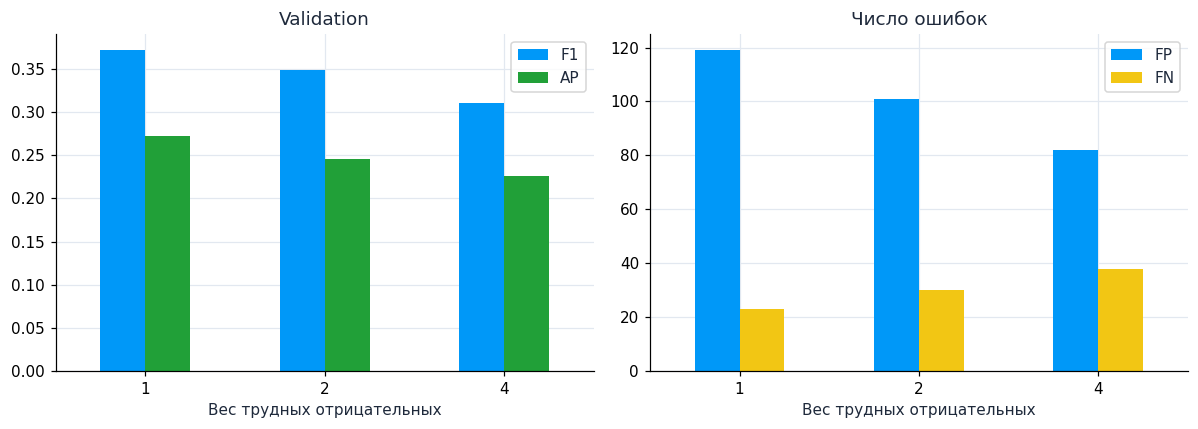

In [7]:
display(table[['weight', 'FP_noisy', 'FP_other', 'FN_noisy', 'FN_other']])
group_rows = []
for row in table.itertuples():
    answer = probabilities[f'weight_{row.weight}'].to_numpy() >= row.Threshold
    for name, mask in [('noisy=1', val_noisy), ('noisy=0', ~val_noisy)]:
        positives = mask & (y_val == 1)
        negatives = mask & (y_val == 0)
        group_rows.append({'weight': row.weight, 'group': name,
                           'positives': int(positives.sum()), 'negatives': int(negatives.sum()),
                           'Recall': answer[positives].mean(), 'FPR': answer[negatives].mean()})
group_metrics = pd.DataFrame(group_rows)
display(group_metrics.round(4))
group_metrics.to_csv(out / 'group_metrics.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
table.set_index('weight')[['F1', 'AP']].plot.bar(ax=axes[0], color=['#0098F8', '#21A038'], rot=0)
table.set_index('weight')[['FP', 'FN']].plot.bar(ax=axes[1], color=['#0098F8', '#F2C614'], rot=0)
axes[0].set(title='Validation', xlabel='Вес трудных отрицательных')
axes[1].set(title='Число ошибок', xlabel='Вес трудных отрицательных')
plt.tight_layout()
plt.show()

## 8. Что изменилось на примерах

Разбираем лучший по F1 вариант среди весов 2 и 4, даже если он хуже исходной модели. Выбор и пороги сделаны на одной validation, поэтому результат пока может быть оптимистичным.

Исправленные FP | всего: 37


,item_id,artifacts,noisy,baseline_p,candidate_p,baseline_prediction,candidate_prediction
1025,c2034de1-858f-47a6-978c-4f85b3794262,0,0,0.1174,0.0695,1,0
424,4f37b7d8-14f4-4c6b-9d0d-3a30b2b4c7f0,0,1,0.1087,0.0691,1,0
681,82e5987a-769d-4d2c-bdbe-7453d12d8450,0,1,0.1073,0.0687,1,0


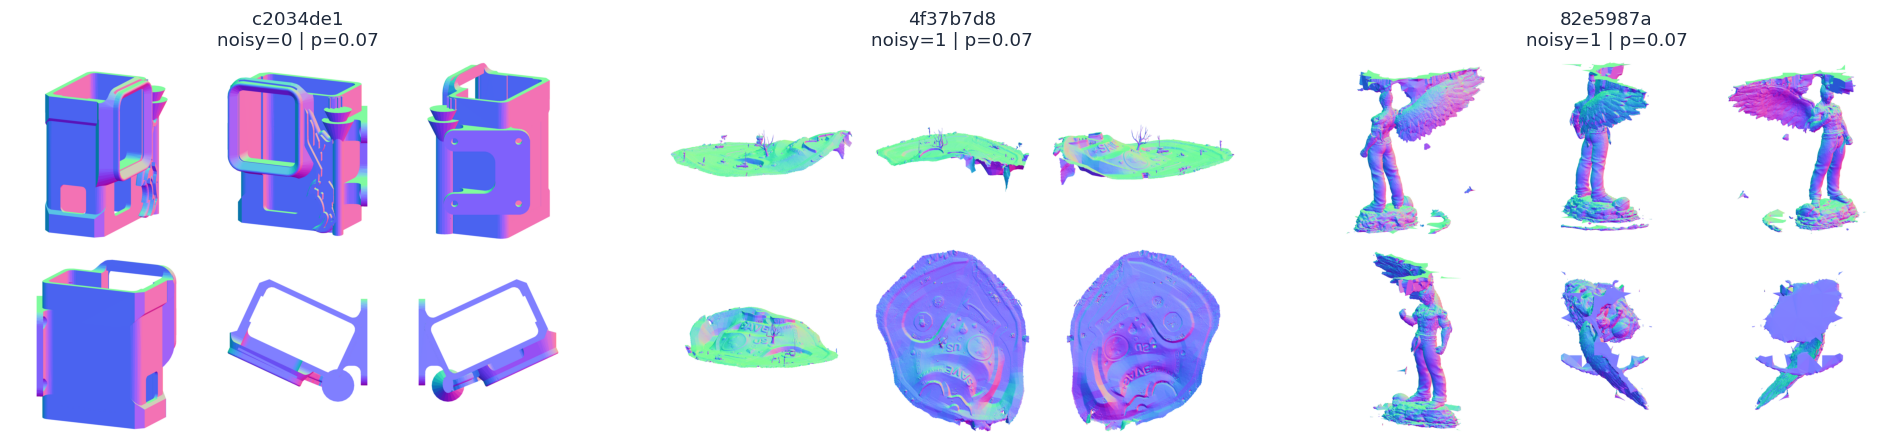

Новые FN | всего: 7


,item_id,artifacts,noisy,baseline_p,candidate_p,baseline_prediction,candidate_prediction
941,b00334f0-9d59-47bc-b28c-305f257e32f0,1,0,0.1144,0.0685,1,0
1264,efa7e697-9398-4dae-8423-44beb9768a28,1,0,0.0807,0.0656,1,0
784,942506b3-004b-4174-8ee0-8315326409d0,1,0,0.1079,0.0650,1,0


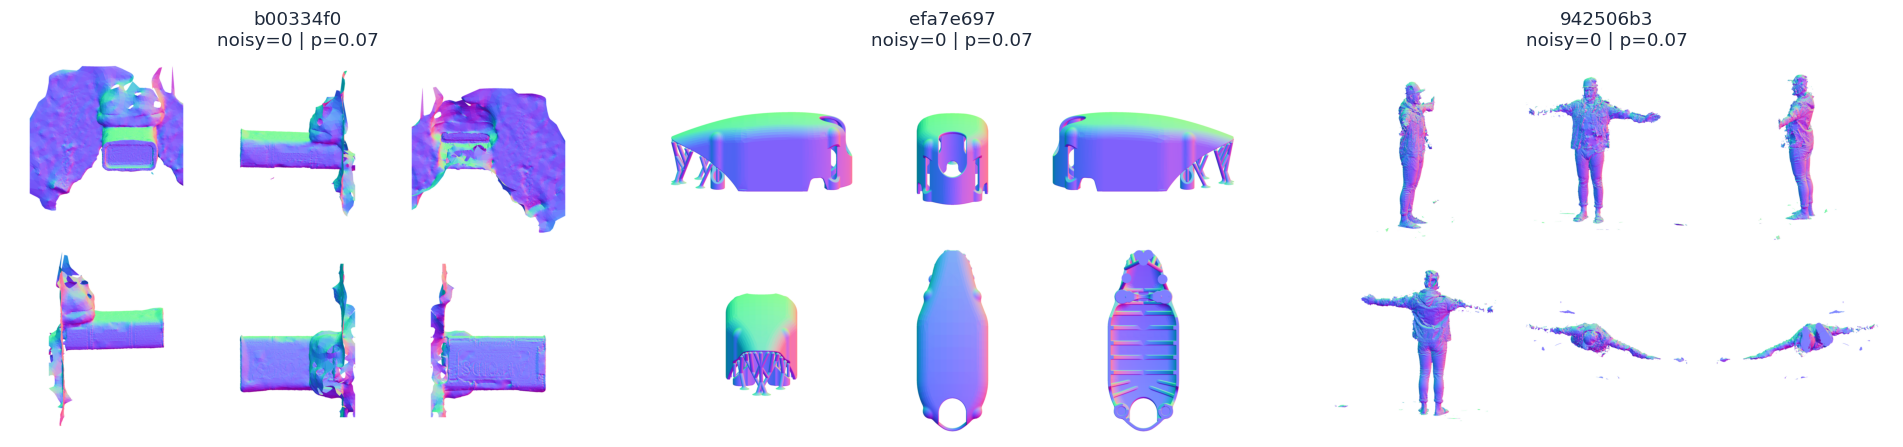

Оставшиеся FP с noisy | всего: 57


,item_id,artifacts,noisy,baseline_p,candidate_p,baseline_prediction,candidate_prediction
735,8b246532-6e2a-47d0-bb1c-3eeaade5ac88,0,1,0.3617,0.4276,1,1
300,3993e9e6-5292-4fcc-87fb-9d382c9cc4bb,0,1,0.3489,0.3661,1,1
1309,f6b75f95-1b42-44cd-b408-04a61709c808,0,1,0.3955,0.3042,1,1


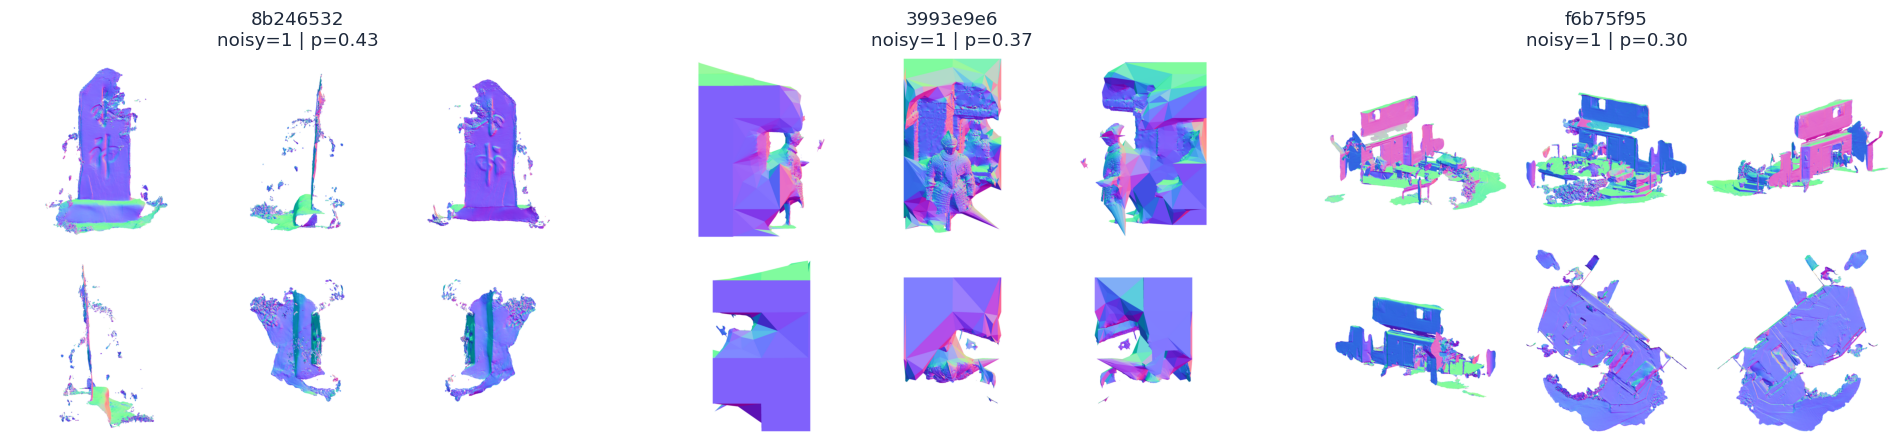

In [3]:
candidate = table[table.weight > 1].sort_values(['F1', 'AP'], ascending=False).iloc[0]
candidate_weight = int(candidate.weight)
original = probabilities.weight_1.to_numpy() >= table.iloc[0].Threshold
candidate_p = probabilities[f'weight_{candidate_weight}'].to_numpy()
answer = candidate_p >= candidate.Threshold
cases = val[['item_id', 'artifacts', 'noisy']].copy()
cases['baseline_p'] = probabilities.weight_1.to_numpy()
cases['candidate_p'] = candidate_p
cases['baseline_prediction'] = original.astype(int)
cases['candidate_prediction'] = answer.astype(int)
cases.to_csv(out / 'cases.csv', index=False)

for title, mask in [
    ('Исправленные FP', (y_val == 0) & original & ~answer),
    ('Новые FN', (y_val == 1) & original & ~answer),
    ('Оставшиеся FP с noisy', (y_val == 0) & val_noisy & answer),
]:
    rows = cases[mask].sort_values('candidate_p', ascending=False).head(3)
    print(title, '| всего:', int(mask.sum()))
    display(rows.round(4))
    if len(rows):
        fig, axes = plt.subplots(1, len(rows), figsize=(6 * len(rows), 4), squeeze=False)
        for ax, row in zip(axes.flat, rows.itertuples()):
            with Image.open(ROOT / 'data/train' / f'{row.item_id}.png') as image:
                ax.imshow(image)
            ax.set_title(f'{row.item_id[:8]}\nnoisy={row.noisy} | p={row.candidate_p:.2f}')
            ax.axis('off')
        plt.tight_layout()
        plt.show()

## Итог

Вес 2 уменьшил FP со 119 до 101, но FN выросли с 23 до 30. F1 упал с **.3717 до .3483**, AP — с **.2724 до .2458**. Вес 4 оказался ещё хуже: F1 **.3103**.

На объектах с обеими метками Recall снизился с .7083 до .5833 при весе 2 и до .3750 при весе 4. Модель стала реже принимать шум за artifacts, но вместе с этим стала пропускать настоящие повреждения.

Среди новых пропусков есть скан человека с `noisy=0`. У оставшихся FP видны рваные края и отдельные фрагменты, но по разметке это `noisy=1, artifacts=0`. Внешне эти случаи похожи.

Повышение веса всей группы noisy не дало прироста. Оставляем прежний DINOv2 + геометрию. Поиск отдельных трудных примеров по OOF-предсказаниям здесь не проверяли. Test не использовали.